# Convolutions


1. What a convolution does to an image
2. Implement it from scratch
3. Classic kernels: edges, blur, sharpen
4. Kernel size → feature scale
5. Kernels are just pattern matchers (this is what CNNs learn)

## The maths

Slide a small matrix (the kernel) across the image. At every position: multiply overlapping pixels with kernel values, add everything up → one output pixel.

$$(I \ast K)(i, j) = \sum_{u=-r}^{r} \sum_{v=-r}^{r} I(i+u,\, j+v)\; K(u, v), \qquad r = \left\lfloor k/2 \right\rfloor$$

With padding $P$ and stride $S$, the output size is:

$$O = \left\lfloor \frac{N + 2P - k}{S} \right\rfloor + 1$$



## Cameraman

Found this guy 

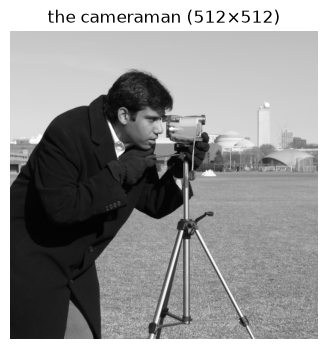

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.camera().astype(np.float32) / 255  # floats in [0, 1] are easier to work with

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title("the cameraman")
plt.axis("off")
plt.show()


## Convolution from scratch

Slide → multiply → sum. That's genuinely all of it:

In [3]:
def conv2d(img, kernel, pad=0, stride=1):
    kh, kw = kernel.shape
    out_h = (img.shape[0] + 2 * pad - kh) // stride + 1   # standard conv output size
    out_w = (img.shape[1] + 2 * pad - kw) // stride + 1
    padded = np.pad(img, pad)                             # ring of zeros around the image
    out = np.zeros((out_h, out_w))
    for i in range(0, out_h * stride, stride):            # slide the kernel down...
        for j in range(0, out_w * stride, stride):        # ...and across
            patch = padded[i:i + kh, j:j + kw]
            out[i // stride, j // stride] = (patch * kernel).sum()  # multiply, then sum
    return out


One output pixel, by hand

In [ ]:
rng = np.random.default_rng(0)
tiny = rng.integers(0, 9, (6, 6)).astype(float)
kernel = np.array([[1, 0, -1],
                   [2, 0, -2],
                   [1, 0, -1]], dtype=float)  # sobel: responds to vertical edges

patch = tiny[:3, :3]  # the top-left window of the image
print("image patch:\n", patch)
print("\nkernel:\n", kernel)
print("\npatch * kernel:\n", patch * kernel)
print("\nsum -> output[0, 0] =", (patch * kernel).sum())  # one number per window


image patch:
 [[7. 5. 4.]
 [0. 0. 1.]
 [4. 5. 8.]]

kernel:
 [[ 1.  0. -1.]
 [ 2.  0. -2.]
 [ 1.  0. -1.]]

patch * kernel:
 [[ 7.  0. -4.]
 [ 0.  0. -2.]
 [ 4.  0. -8.]]

sum -> output[0, 0] = -3.0


Same thing on the real image. Kernel = 9×9 box blur (every value 1/81), so the output is just the local mean. Four different windows, four different answers:

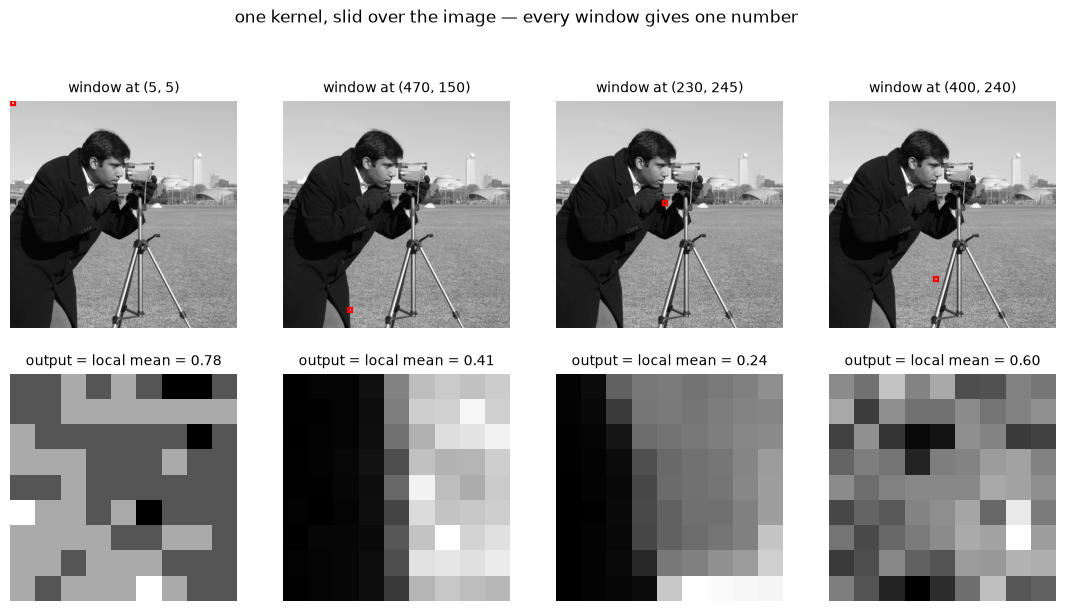

In [8]:
kernel = np.ones((9, 9)) / 81  # box blur: every window becomes its local mean
windows = [(5, 5), (470, 150), (230, 245), (400, 240)]   # (row, col)

fig, axes = plt.subplots(2, len(windows), figsize=(13.5, 6.5))
for ax, (r, c) in zip(axes[0], windows):
    ax.imshow(img, cmap="gray")
    ax.add_patch(plt.Rectangle((c - 4, r - 4), 9, 9, color="red", fill=False, lw=1.6))  # mark the 9x9 window
    ax.set_title("window", fontsize=10)
    ax.axis("off")
for ax, (r, c) in zip(axes[1], windows):
    patch = img[r - 4:r + 5, c - 4:c + 5]  # the window: centre row/col plus or minus 4
    ax.imshow(patch, cmap="gray")
    ax.set_title("output = local mean", fontsize=10)
    ax.axis("off")
plt.suptitle("one kernel, slid over the image — every window gives one number", y=1.02)
plt.show()


## Classic kernels

People spent decades designing these by hand. Each one fires on a specific pattern:

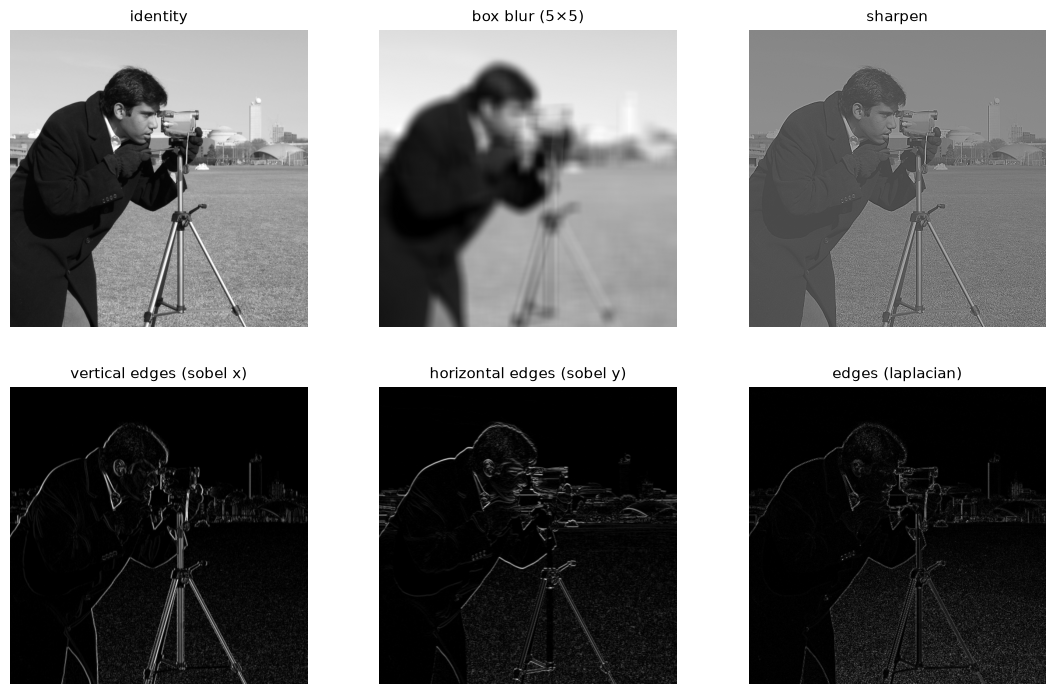

In [9]:
kernels = {
    "identity": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
    "box blur (5×5)": np.ones((20, 20)) / 400,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
    "vertical edges (sobel x)": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float),
    "horizontal edges (sobel y)": np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], float),
    "edges (laplacian)": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float),
}

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
for ax, (name, k) in zip(axes.flat, kernels.items()):
    out = conv2d(img, k)
    if "edge" in name:
        out = np.abs(out)  # edges fire positive or negative; keep the magnitude
    ax.imshow(out, cmap="gray")
    ax.set_title(name, fontsize=11)
    ax.axis("off")
plt.show()


Vertical-edge kernel lights up vertical lines, horizontal one lights up horizontal lines. The kernel values decide which feature gets detected.

## Kernel size → feature scale

Zero-sum centre-surround kernel: $1$ in the middle, $-\tfrac{1}{k^2-1}$ everywhere else. It responds to any local contrast *smaller than the kernel*; anything bigger averages out. Grow $k$ and watch the features fall away:

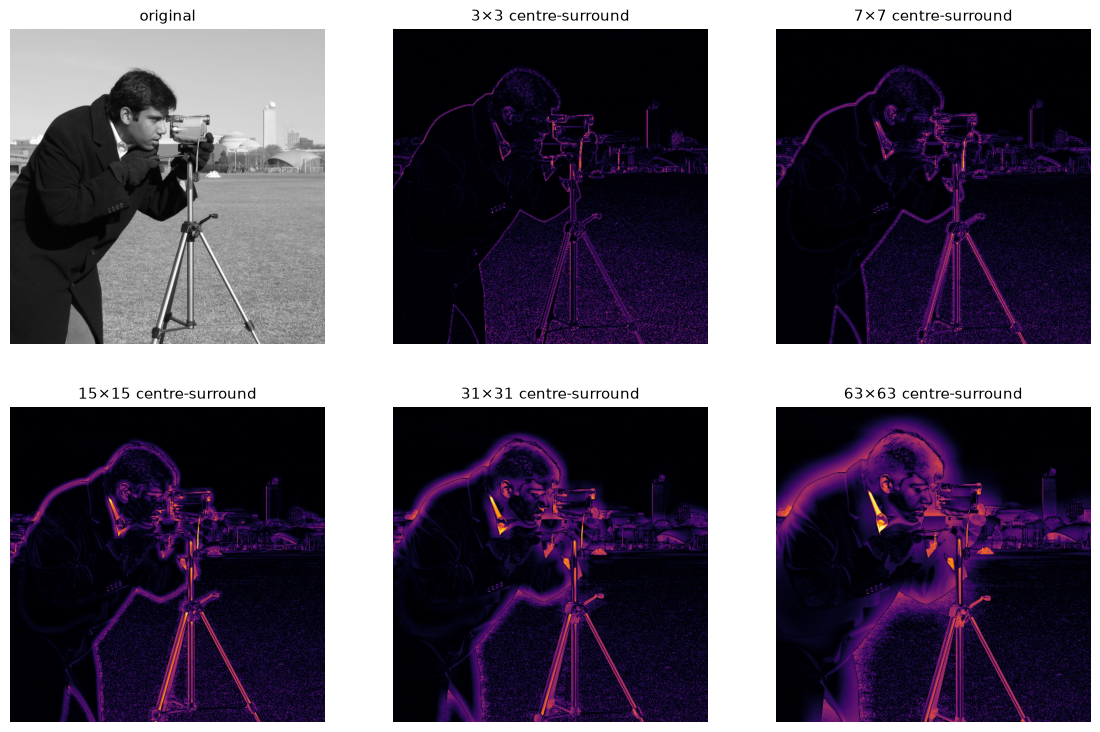

In [6]:
def centre_surround(k):
    K = -np.ones((k, k)) / (k * k - 1)   # weak negative ring...
    K[k // 2, k // 2] = 1.0              # ...around a strong centre; sums to zero
    return K

sizes = [3, 7, 15, 31, 63]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes.flat[0].imshow(img, cmap="gray")
axes.flat[0].set_title("original", fontsize=11)
axes.flat[0].axis("off")
for ax, k in zip(axes.flat[1:], sizes):
    ax.imshow(np.abs(conv2d(img, centre_surround(k))), cmap="inferno")  # bigger kernel, bigger features
    ax.set_title("centre-surround", fontsize=11)
    ax.axis("off")
plt.show()


3×3 chases the grass texture. 15×15 is already mostly edges. 63×63 only sees the big stuff: tripod, camera body, head. The kernel size decides the scale of the feature.

## A kernel is a pattern matcher

Let's not design a kernel at all; just cut a patch out of the image itself, subtract its mean, and use *it* as the kernel. The output now answers, at every position: *how much does the image look like this patch here?*

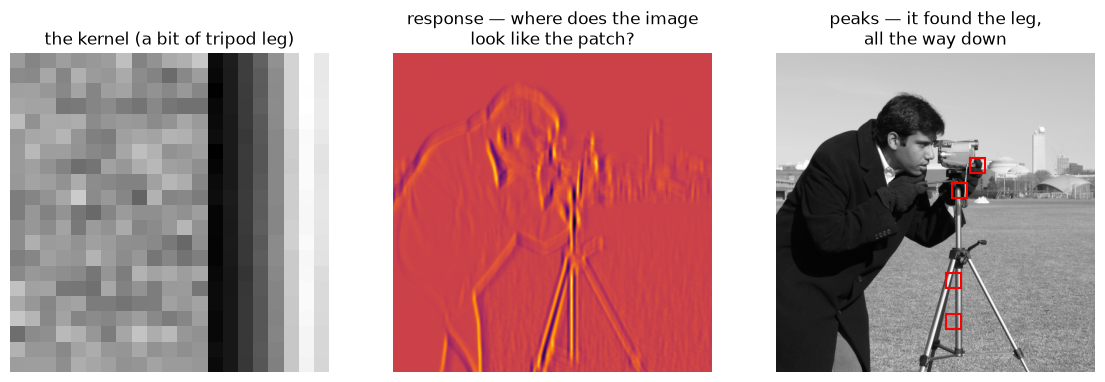

In [7]:
r, c, s = 420, 275, 21                    # a slice of tripod leg
patch = img[r:r + s, c:c + s]
K = patch - patch.mean()   # zero-mean: match pattern, not brightness
K /= np.linalg.norm(K)     # unit length

response = conv2d(img, K)  # high wherever the image looks like the patch

# top-4 peaks, suppressing nearby duplicates
resp = response.copy()
peaks = []
for _ in range(4):
    i, j = np.unravel_index(resp.argmax(), resp.shape)  # flat argmax -> (row, col)
    peaks.append((j, i))
    resp[max(0, i - 40):i + 40, max(0, j - 40):j + 40] = -np.inf  # blank the neighbourhood, find the next peak

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(patch, cmap="gray")
axes[0].set_title("the kernel (a bit of tripod leg)")
axes[1].imshow(response, cmap="inferno")
axes[1].set_title("response — where does the image\nlook like the patch?")
axes[2].imshow(img, cmap="gray")
for j, i in peaks:
    axes[2].add_patch(plt.Rectangle((j - 2, i - 2), s + 3, s + 3, color="red", fill=False, lw=1.5))
axes[2].set_title("peaks — it found the leg,\nall the way down")
for ax in axes:
    ax.axis("off")
plt.show()
